
   STUDENT PERFORMANCE ANALYZER
1. Display All Students
2. Add New Student
3. Search Student
4. Update Student Record
5. Delete Student Record
6. Generate Student Reports
7. Analyze Class Performance
8. Display Student Ranking
9. Show Data Visualization
10. Load Records from CSV
11. Save Records to CSV
12. Exit

Enter your choice (1-12): 1

========== STUDENT RECORDS ==========
 Name  Python  Maths  DBMS  Attendance  Study_Hours
Rahul      78     82    75          85            3
Priya      88     91    85          92            5
 Aman      35     42    38          68            1
Sneha      55     58    52          72            2

   STUDENT PERFORMANCE ANALYZER
1. Display All Students
2. Add New Student
3. Search Student
4. Update Student Record
5. Delete Student Record
6. Generate Student Reports
7. Analyze Class Performance
8. Display Student Ranking
9. Show Data Visualization
10. Load Records from CSV
11. Save Records to CSV
12. Exit

Enter your choice (1-12): 2

========== ADD

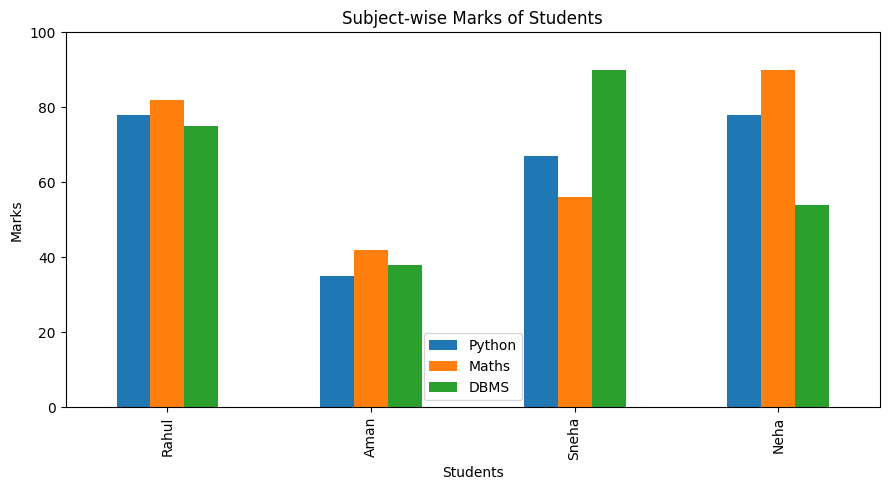

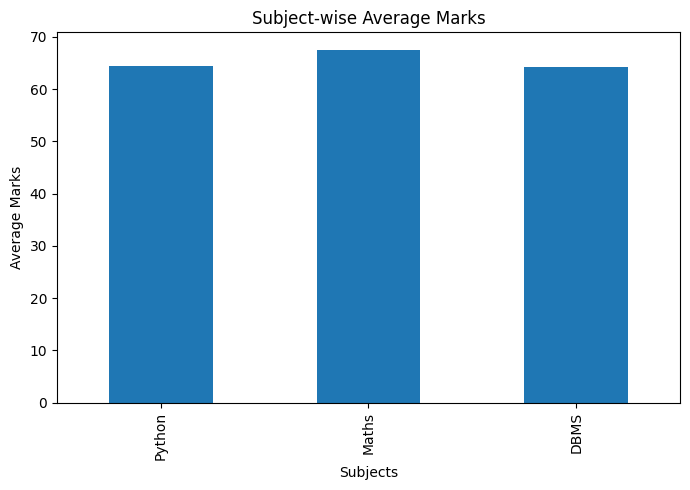

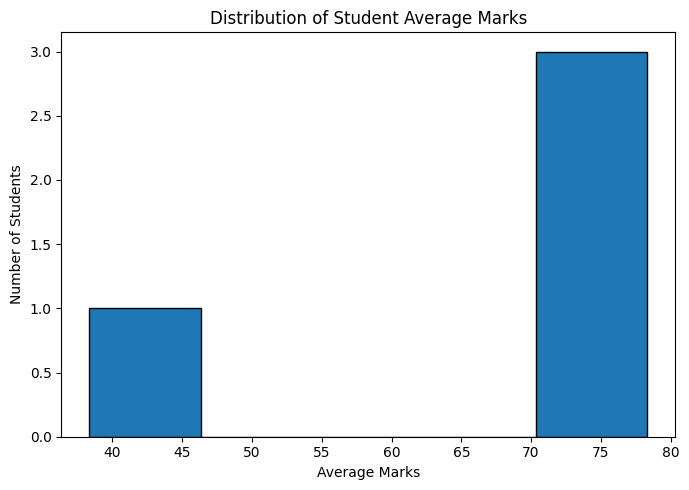

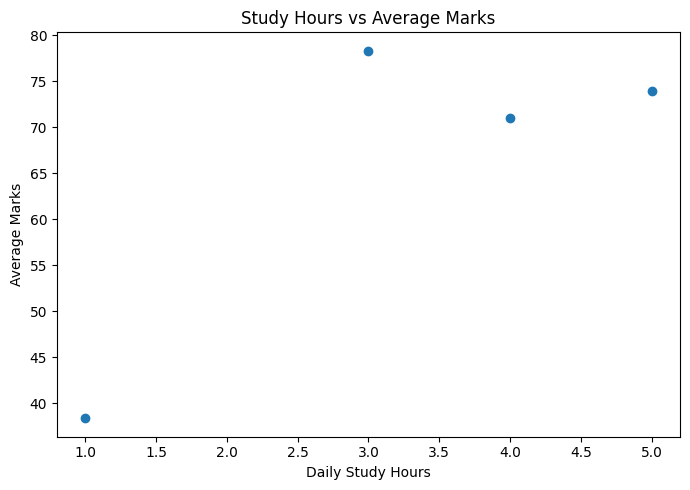


   STUDENT PERFORMANCE ANALYZER
1. Display All Students
2. Add New Student
3. Search Student
4. Update Student Record
5. Delete Student Record
6. Generate Student Reports
7. Analyze Class Performance
8. Display Student Ranking
9. Show Data Visualization
10. Load Records from CSV
11. Save Records to CSV
12. Exit

Enter your choice (1-12): 10

Records loaded successfully!

========== STUDENT RECORDS ==========
 Name  Python  Maths  DBMS  Attendance  Study_Hours
Rahul    78.0   82.0  75.0        85.0          3.0
 Aman    35.0   42.0  38.0        68.0          1.0
Sneha    67.0   56.0  90.0        82.0          4.0
 Neha    78.0   90.0  54.0        49.0          5.0

   STUDENT PERFORMANCE ANALYZER
1. Display All Students
2. Add New Student
3. Search Student
4. Update Student Record
5. Delete Student Record
6. Generate Student Reports
7. Analyze Class Performance
8. Display Student Ranking
9. Show Data Visualization
10. Load Records from CSV
11. Save Records to CSV
12. Exit

Enter your c

In [3]:

# STUDENT PERFORMANCE ANALYZER
# BCA 2nd Year Final Project

import os
import pandas as pd
import matplotlib.pyplot as plt


# 1. PROJECT SETUP AND DATASET

FILE_NAME = "student_records.csv"

initial_students = [
    ["Rahul", 78, 82, 75, 85, 3],
    ["Priya", 88, 91, 85, 92, 5],
    ["Aman", 35, 42, 38, 68, 1],
    ["Sneha", 55, 58, 52, 72, 2]
]

COLUMNS = [
    "Name", "Python", "Maths", "DBMS",
    "Attendance", "Study_Hours"
]

if os.path.exists(FILE_NAME):
    df = pd.read_csv(FILE_NAME)

    if "Study_Hours" not in df.columns:
        study_hours = {
            "Rahul": 3,
            "Priya": 5,
            "Aman": 1,
            "Sneha": 2
        }
        df["Study_Hours"] = df["Name"].map(
            study_hours
        ).fillna(0)

    for column in COLUMNS:
        if column not in df.columns:
            df[column] = 0

    df = df[COLUMNS]

else:
    df = pd.DataFrame(
        initial_students,
        columns=COLUMNS
    )

df.to_csv(FILE_NAME, index=False)


# 2. PERFORMANCE AND GRADE FUNCTIONS

def calculate_average(student):
    return (
        student["Python"] +
        student["Maths"] +
        student["DBMS"]
    ) / 3


def get_performance(average):
    if average >= 80:
        return "Excellent"
    elif average >= 60:
        return "Good"
    elif average >= 40:
        return "Average"
    else:
        return "Needs Improvement"


def get_grade(average):
    if average >= 90:
        return "A+"
    elif average >= 80:
        return "A"
    elif average >= 70:
        return "B"
    elif average >= 60:
        return "C"
    elif average >= 40:
        return "D"
    else:
        return "F"


def get_pass_status(student):
    subjects = ["Python", "Maths", "DBMS"]

    if all(student[subject] >= 40 for subject in subjects):
        return "Pass"

    return "Fail"


def get_attendance_status(attendance):
    if attendance >= 75:
        return "Good Attendance"

    return "Low Attendance"


# 3. INPUT VALIDATION

def get_valid_number(message, minimum=0, maximum=100):
    while True:
        try:
            value = float(input(message))

            if minimum <= value <= maximum:
                return value

            print(f"Enter a value between {minimum} and {maximum}.")

        except ValueError:
            print("Please enter a valid number.")


def get_valid_name(message):
    while True:
        name = input(message).strip()

        if name:
            return name

        print("Name cannot be empty.")


# 4. DISPLAY STUDENT RECORDS

def display_students():
    if df.empty:
        print("\nNo student records available.")
    else:
        print("\n========== STUDENT RECORDS ==========")
        print(df.to_string(index=False))


# 5. ADD A NEW STUDENT

def add_student():
    global df

    print("\n========== ADD STUDENT ==========")

    name = get_valid_name("Enter student name: ")

    if name.lower() in df["Name"].astype(str).str.lower().values:
        print("Student already exists.")
        return

    python = get_valid_number("Enter Python marks: ")
    maths = get_valid_number("Enter Maths marks: ")
    dbms = get_valid_number("Enter DBMS marks: ")
    attendance = get_valid_number("Enter attendance: ")
    study_hours = get_valid_number(
        "Enter daily study hours: ", 0, 24
    )

    new_student = pd.DataFrame([{
        "Name": name,
        "Python": python,
        "Maths": maths,
        "DBMS": dbms,
        "Attendance": attendance,
        "Study_Hours": study_hours
    }])

    df = pd.concat(
        [df, new_student],
        ignore_index=True
    )

    save_data()
    print("Student added successfully!")


# 6. SEARCH STUDENT

def search_student():
    name = input("\nEnter student name to search: ").strip()

    result = df[
        df["Name"].astype(str).str.lower() == name.lower()
    ]

    if result.empty:
        print("Student not found.")
    else:
        print(result.to_string(index=False))


# 7. UPDATE STUDENT RECORD

def update_student():
    global df

    name = input("\nEnter student name to update: ").strip()

    matches = df.index[
        df["Name"].astype(str).str.lower() == name.lower()
    ].tolist()

    if not matches:
        print("Student not found.")
        return

    index = matches[0]

    print("\nEnter updated information:")

    df.at[index, "Python"] = get_valid_number("Python marks: ")
    df.at[index, "Maths"] = get_valid_number("Maths marks: ")
    df.at[index, "DBMS"] = get_valid_number("DBMS marks: ")
    df.at[index, "Attendance"] = get_valid_number("Attendance: ")
    df.at[index, "Study_Hours"] = get_valid_number(
        "Daily study hours: ", 0, 24
    )

    save_data()
    print("Record updated successfully!")


# 8. DELETE STUDENT RECORD

def delete_student():
    global df

    name = input("\nEnter student name to delete: ").strip()

    matches = df[
        df["Name"].astype(str).str.lower() == name.lower()
    ]

    if matches.empty:
        print("Student not found.")
        return

    df = df[
        df["Name"].astype(str).str.lower() != name.lower()
    ].reset_index(drop=True)

    save_data()
    print("Student deleted successfully!")


# 9. SAVE AND LOAD CSV DATA

def save_data():
    df.to_csv(FILE_NAME, index=False)
    print("Records saved successfully.")


def load_data():
    global df

    df = pd.read_csv(FILE_NAME)
    print("\nRecords loaded successfully!")
    display_students()


# 10. GENERATE STUDENT REPORTS

def generate_reports():
    if df.empty:
        print("No student records available.")
        return

    print("\n========== STUDENT PERFORMANCE REPORT ==========")

    for _, student in df.iterrows():

        average = calculate_average(student)

        print("\nStudent Name:", student["Name"])
        print("Python Marks:", student["Python"])
        print("Maths Marks:", student["Maths"])
        print("DBMS Marks:", student["DBMS"])
        print("Average Marks:", round(average, 2))
        print("Grade:", get_grade(average))
        print("Performance:", get_performance(average))
        print("Result:", get_pass_status(student))
        print(
            "Attendance:",
            get_attendance_status(student["Attendance"])
        )


# 11. CLASS STATISTICS AND DATA ANALYSIS

def analyze_data():
    if df.empty:
        print("No student records available.")
        return

    analysis_df = df.copy()

    analysis_df["Average"] = analysis_df.apply(
        calculate_average, axis=1
    )

    analysis_df["Performance"] = analysis_df["Average"].apply(
        get_performance
    )

    print("\n========== CLASS ANALYSIS ==========")

    print("\nTotal Students:", len(analysis_df))

    print("\nSubject-wise Average Marks:")
    print(
        analysis_df[["Python", "Maths", "DBMS"]]
        .mean().round(2)
    )

    print("\nOverall Class Average:",
          round(analysis_df["Average"].mean(), 2))

    print("\nHighest Average:",
          round(analysis_df["Average"].max(), 2))

    print("\nLowest Average:",
          round(analysis_df["Average"].min(), 2))

    print("\nPerformance Category Count:")
    print(analysis_df["Performance"].value_counts())

    print("\nClass Topper:")
    topper = analysis_df.loc[
        analysis_df["Average"].idxmax()
    ]
    print(topper["Name"], "-", round(topper["Average"], 2))

    print("\nStudents Needing Support:")
    support = analysis_df[
        analysis_df["Performance"] == "Needs Improvement"
    ]

    if support.empty:
        print("No students in this category.")
    else:
        print(support["Name"].to_string(index=False))

    print("\nPass and Fail Summary:")
    print(
        analysis_df.apply(
            get_pass_status, axis=1
        ).value_counts()
    )


# 12. DATA VISUALIZATION USING MATPLOTLIB

def show_charts():
    if df.empty:
        print("No student records available.")
        return

    chart_df = df.copy()

    chart_df["Average"] = chart_df.apply(
        calculate_average, axis=1
    )

    # Chart 1: Student-wise subject marks

    chart_df.plot(
        x="Name",
        y=["Python", "Maths", "DBMS"],
        kind="bar",
        figsize=(9, 5)
    )

    plt.title("Subject-wise Marks of Students")
    plt.xlabel("Students")
    plt.ylabel("Marks")
    plt.ylim(0, 100)
    plt.tight_layout()
    plt.show()

    # Chart 2: Subject-wise average marks

    subject_average = chart_df[
        ["Python", "Maths", "DBMS"]
    ].mean()

    subject_average.plot(
        kind="bar",
        figsize=(7, 5)
    )

    plt.title("Subject-wise Average Marks")
    plt.xlabel("Subjects")
    plt.ylabel("Average Marks")
    plt.tight_layout()
    plt.show()

    # Chart 3: Distribution of average marks

    plt.figure(figsize=(7, 5))

    plt.hist(
        chart_df["Average"],
        bins=5,
        edgecolor="black"
    )

    plt.title("Distribution of Student Average Marks")
    plt.xlabel("Average Marks")
    plt.ylabel("Number of Students")
    plt.tight_layout()
    plt.show()

    # Chart 4: Study hours vs average marks

    plt.figure(figsize=(7, 5))

    plt.scatter(
        chart_df["Study_Hours"],
        chart_df["Average"]
    )

    plt.title("Study Hours vs Average Marks")
    plt.xlabel("Daily Study Hours")
    plt.ylabel("Average Marks")
    plt.tight_layout()
    plt.show()


# 13. RANK STUDENTS

def rank_students():
    if df.empty:
        print("No student records available.")
        return

    ranking = df.copy()

    ranking["Average"] = ranking.apply(
        calculate_average, axis=1
    )

    ranking = ranking.sort_values(
        by="Average",
        ascending=False
    )

    print("\n========== STUDENT RANKING ==========")

    for rank, (_, student) in enumerate(
        ranking.iterrows(), start=1
    ):
        print(
            rank,
            student["Name"],
            "-",
            round(student["Average"], 2)
        )


# 14. MAIN MENU

def main():

    while True:

        print("\n========================================")
        print("   STUDENT PERFORMANCE ANALYZER")
        print("========================================")

        print("1. Display All Students")
        print("2. Add New Student")
        print("3. Search Student")
        print("4. Update Student Record")
        print("5. Delete Student Record")
        print("6. Generate Student Reports")
        print("7. Analyze Class Performance")
        print("8. Display Student Ranking")
        print("9. Show Data Visualization")
        print("10. Load Records from CSV")
        print("11. Save Records to CSV")
        print("12. Exit")

        choice = input("\nEnter your choice (1-12): ")

        if choice == "1":
            display_students()

        elif choice == "2":
            add_student()

        elif choice == "3":
            search_student()

        elif choice == "4":
            update_student()

        elif choice == "5":
            delete_student()

        elif choice == "6":
            generate_reports()

        elif choice == "7":
            analyze_data()

        elif choice == "8":
            rank_students()

        elif choice == "9":
            show_charts()

        elif choice == "10":
            load_data()

        elif choice == "11":
            save_data()

        elif choice == "12":
            print("\nThank you for using Student Performance Analyzer!")
            break

        else:
            print("Invalid choice. Please try again.")


# 15. RUN THE PROJECT

main()
